
# 📊 EVALUATION — Task A & Task B (Test Set + Grad-CAM)

Notebook này **KHÔNG train** — chỉ tải các model tốt nhất đã lưu trên Google Drive (từ `TaskA_Binary_Classification.ipynb` và `TaskB_Multiclass_Classification.ipynb`), đánh giá trên **tập TEST** (chưa từng được dùng để train/chọn checkpoint ở 2 notebook kia), sinh Grad-CAM, và tổng hợp bảng so sánh xếp hạng model tốt nhất cho từng task.

Cấu trúc:
1. Cài đặt & tiện ích dùng chung (Task A + Task B)
2. **SECTION — TASK A**: đánh giá `resnet50`, `convnext_base` → bảng so sánh → model tốt nhất
3. **SECTION — TASK B**: đánh giá `resnet50`, `convnext_base`, `efficientnetv2_m`, `swin_base`, `vit_base`, `dinov2` → bảng so sánh → model tốt nhất
4. Tổng kết cuối cùng

⚠️ Notebook này yêu cầu file `taskA_split.json` / `taskB_split.json` đã tồn tại trên Drive (được tạo tự động khi bạn chạy 2 notebook train lần đầu). Nếu thiếu, hãy chạy notebook train tương ứng trước (dù chỉ 0 epoch) để sinh ra file split.


## 1. Cài đặt thư viện

In [1]:

!pip install -q timm==1.0.11 scikit-learn seaborn grad-cam


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.4/48.4 kB 2.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 3.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 50.2 MB/s eta 0:00:00


## 2. Import & thiết lập seed / device

In [3]:

import os, sys, json, math, random, shutil, zipfile, glob
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import timm
from timm.data import resolve_data_config
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                              recall_score, confusion_matrix, classification_report)
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Thiết bị đang sử dụng: {device}")
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Thiết bị đang sử dụng: cpu


## 3. Kết nối Google Drive & định nghĩa đường dẫn

In [4]:

from google.colab import drive
drive.mount('/content/drive')

DRIVE_ROOT       = "/content/drive/MyDrive/SpermAI_Benchmark"
DATA_DRIVE_DIR   = f"{DRIVE_ROOT}/data"

MODELS_DIR_A = f"{DRIVE_ROOT}/outputs/TaskA"          # nơi 2 notebook train đã lưu best_model.pth
MODELS_DIR_B = f"{DRIVE_ROOT}/outputs/TaskB"

EVAL_DIR_A = f"{DRIVE_ROOT}/outputs/Evaluation/TaskA"  # nơi notebook NÀY lưu kết quả đánh giá test + Grad-CAM
EVAL_DIR_B = f"{DRIVE_ROOT}/outputs/Evaluation/TaskB"
os.makedirs(EVAL_DIR_A, exist_ok=True)
os.makedirs(EVAL_DIR_B, exist_ok=True)

LOCAL_ROOT = "/content/sperm_data"
RAW_ROOT   = f"{LOCAL_ROOT}/raw_extracted"
RAW_ZIP_PATH = f"{LOCAL_ROOT}/dataset_download.zip"
os.makedirs(LOCAL_ROOT, exist_ok=True)

# FORCE_RECOMPUTE = True -> luôn đánh giá lại dù đã có kết quả cũ trong EVAL_DIR (hữu ích khi bạn train lại 1 model)
FORCE_RECOMPUTE = False

print("MODELS_DIR_A:", MODELS_DIR_A)
print("MODELS_DIR_B:", MODELS_DIR_B)
print("EVAL_DIR_A  :", EVAL_DIR_A)
print("EVAL_DIR_B  :", EVAL_DIR_B)


Mounted at /content/drive
MODELS_DIR_A: /content/drive/MyDrive/SpermAI_Benchmark/outputs/TaskA
MODELS_DIR_B: /content/drive/MyDrive/SpermAI_Benchmark/outputs/TaskB
EVAL_DIR_A  : /content/drive/MyDrive/SpermAI_Benchmark/outputs/Evaluation/TaskA
EVAL_DIR_B  : /content/drive/MyDrive/SpermAI_Benchmark/outputs/Evaluation/TaskB


## 4. Tải & giải nén dataset gốc (để lấy ảnh của tập TEST) — idempotent, giống 2 notebook train

In [6]:
import subprocess

FIGSHARE_ARTICLE_ID   = "30120811"
FIGSHARE_DOWNLOAD_URL = f"https://ndownloader.figshare.com/articles/{FIGSHARE_ARTICLE_ID}/versions/1"
DRIVE_CACHED_ZIP      = f"{DATA_DRIVE_DIR}/figshare_raw_dataset.zip"

def _find_dir(root, keyword):
    """Tìm (đệ quy) thư mục có tên chứa `keyword` (không phân biệt hoa/thường)."""
    keyword = keyword.lower()
    for dirpath, dirnames, _ in os.walk(root):
        for d in dirnames:
            if keyword in d.lower():
                return os.path.join(dirpath, d)
    return None

def _extract_recursive(zip_path, dest):
    """Giải nén archive Figshare bằng unrar.
    File Figshare có thể mang đuôi .zip nhưng thực tế chứa archive RAR
    (bên trong có Dataset/ và các thư mục dữ liệu thật)."""
    result = subprocess.run(
        ["unrar", "x", "-o+", "-p-", zip_path, dest + "/"],
        stdout=subprocess.DEVNULL,
        stderr=subprocess.PIPE,
        text=True
    )

    if result.returncode != 0:
        print(result.stderr)
        raise RuntimeError("Giải nén archive thất bại.")

def dataset_is_ready(root):
    """Dữ liệu thô được coi là sẵn sàng khi tìm thấy cả 2 thư mục nhãn gốc."""
    bin_dir  = _find_dir(root, "Binary Classification")
    halo_dir = _find_dir(root, "Halo Classification")
    ok = bool(bin_dir) and bool(halo_dir)
    if ok:
        print(f"  ✓ Tìm thấy: {bin_dir}")
        print(f"  ✓ Tìm thấy: {halo_dir}")
    return ok

if dataset_is_ready(RAW_ROOT):
    # ƯU TIÊN 1: dữ liệu đã có sẵn trong phần cứng Colab (phiên hiện tại) -> dùng chung, không tải lại
    print("✅ Dữ liệu thô đã có sẵn trong phần cứng Colab (phiên hiện tại) — bỏ qua tải & giải nén (dùng chung giữa các model).")
else:
    os.makedirs(RAW_ROOT, exist_ok=True)
    downloaded = False

    # ƯU TIÊN 2: đã có bản zip cache trên Google Drive (từ lần chạy trước, tự động HOẶC bạn tự upload thủ công)
    if os.path.exists(DRIVE_CACHED_ZIP):
        print("⬇️  Tìm thấy bản zip đã cache trên Google Drive → dùng bản này (KHÔNG tải lại từ Figshare).")
        shutil.copy(DRIVE_CACHED_ZIP, RAW_ZIP_PATH)
        downloaded = True
    else:
        # ƯU TIÊN 3 (chỉ xảy ra ở LẦN CHẠY ĐẦU TIÊN, khi Drive chưa có gì): tải từ Figshare
        print("⬇️  Chưa có bản cache trên Drive — đang tải dataset từ Figshare (chỉ xảy ra ở lần đầu tiên) ...")
        try:
            import urllib.request
            urllib.request.urlretrieve(FIGSHARE_DOWNLOAD_URL, RAW_ZIP_PATH)
            if os.path.getsize(RAW_ZIP_PATH) > 10_000:
                downloaded = True
        except Exception as e:
            print(f"  ✗ Tải từ Figshare thất bại: {e}")

    if not downloaded:
        raise RuntimeError(
            "Không thể tải dataset tự động (không có cache trên Drive, và tải từ Figshare thất bại).\n"
            "→ Hãy tải thủ công file zip tại https://doi.org/10.6084/m9.figshare.30120811,\n"
            f"  upload lên Google Drive đúng đường dẫn: {DRIVE_CACHED_ZIP}\n"
            "  rồi chạy lại cell này."
        )

    print("📦 Đang giải nén ...")
    _extract_recursive(RAW_ZIP_PATH, RAW_ROOT)

    if not dataset_is_ready(RAW_ROOT):
        raise RuntimeError(
            "Giải nén xong nhưng KHÔNG tìm thấy thư mục 'Binary Classification' hoặc 'Halo Classification'.\n"
            "→ Hãy kiểm tra thủ công cấu trúc bên trong RAW_ROOT (dùng lệnh !find) và chỉnh lại hàm _find_dir nếu tên khác."
        )

    # Nếu zip này vừa được tải MỚI từ Figshare (Drive lúc nãy chưa có) -> tự backup lên Drive cho các lần sau.
    # Nếu bạn muốn tự kiểm soát bản cache (tự nén thủ công), chỉ cần upload file của bạn đúng path
    # DRIVE_CACHED_ZIP trước khi chạy cell này — code sẽ ưu tiên dùng bản đó và bỏ qua bước tải Figshare.
    if not os.path.exists(DRIVE_CACHED_ZIP):
        print("☁️  Sao lưu zip gốc lên Drive để các lần chạy sau không cần tải lại từ Figshare ...")
        shutil.copy(RAW_ZIP_PATH, DRIVE_CACHED_ZIP)

    print("✅ Hoàn tất tải & giải nén dataset.")

BINARY_DIR = _find_dir(RAW_ROOT, "Binary Classification")
HALO_DIR   = _find_dir(RAW_ROOT, "Halo Classification")   # không dùng ở Task A, chỉ in ra để kiểm tra
print("\nBINARY_DIR:", BINARY_DIR)
print("HALO_DIR  :", HALO_DIR, " (không dùng trong Task A)")

⬇️  Tìm thấy bản zip đã cache trên Google Drive → dùng bản này (KHÔNG tải lại từ Figshare).
📦 Đang giải nén ...
  ✓ Tìm thấy: /content/sperm_data/raw_extracted/Dataset/Binary Classification
  ✓ Tìm thấy: /content/sperm_data/raw_extracted/Dataset/Halo Classification
✅ Hoàn tất tải & giải nén dataset.

BINARY_DIR: /content/sperm_data/raw_extracted/Dataset/Binary Classification
HALO_DIR  : /content/sperm_data/raw_extracted/Dataset/Halo Classification  (không dùng trong Task A)


## 5. Các hàm dùng chung cho cả 2 Task

In [7]:
IMG_EXTS = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")

def list_all_samples(raw_dir):
    """Quét toàn bộ ảnh + lớp thực tế trong thư mục gốc (dùng để tra path theo (class, filename))."""
    classes = sorted([d for d in os.listdir(raw_dir) if os.path.isdir(os.path.join(raw_dir, d))])
    samples = []
    for cls in classes:
        cls_dir = os.path.join(raw_dir, cls)
        for f in sorted(os.listdir(cls_dir)):
            if f.lower().endswith(IMG_EXTS):
                samples.append({"class": cls, "filename": f, "path": os.path.join(cls_dir, f)})
    return classes, samples


def load_test_list(split_json_path, raw_dir):
    """Load lại đúng tập TEST đã được 2 notebook train chốt cố định — KHÔNG bao giờ tự tạo split ở đây."""
    if not os.path.exists(split_json_path):
        raise FileNotFoundError(
            f"Không tìm thấy '{split_json_path}'.\n"
            "→ Hãy chạy notebook train tương ứng (Task A hoặc Task B) trước để sinh file chia tập cố định, "
            "sau đó mới quay lại notebook Evaluation này."
        )
    with open(split_json_path, "r") as f:
        split_map = json.load(f)

    _, samples = list_all_samples(raw_dir)
    path_lookup = {(r["class"], r["filename"]): r["path"] for r in samples}
    test_list = [(path_lookup[(c, f)], c) for c, f in split_map["test"] if (c, f) in path_lookup]
    return test_list


class SpermDataset(Dataset):
    def __init__(self, items, class_to_idx, transform=None):
        self.items = items
        self.class_to_idx = class_to_idx
        self.transform = transform

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        path, cls = self.items[idx]
        img = Image.open(path).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, self.class_to_idx[cls]


def build_transforms(model, augment=False):
    data_cfg = resolve_data_config({}, model=model)
    img_size = data_cfg["input_size"][-1]
    mean, std = data_cfg["mean"], data_cfg["std"]
    ops = [transforms.Resize((img_size, img_size)), transforms.ToTensor(), transforms.Normalize(mean=mean, std=std)]
    return transforms.Compose(ops)


def discover_trained_models(models_dir):
    """Tự động tìm các model_key đã có best_model.pth + config.json trong thư mục output của notebook train."""
    found = {}
    if not os.path.isdir(models_dir):
        return found
    for model_key in sorted(os.listdir(models_dir)):
        d = os.path.join(models_dir, model_key)
        ckpt = os.path.join(d, "best_model.pth")
        cfg  = os.path.join(d, "config.json")
        if os.path.isfile(ckpt) and os.path.isfile(cfg):
            found[model_key] = {"ckpt": ckpt, "config": cfg}
    return found


@torch.no_grad()
def evaluate_on_test(model, loader):
    model.eval()
    all_preds, all_labels = [], []
    for x, y in loader:
        x = x.to(device)
        out = model(x)
        all_preds.extend(out.argmax(dim=1).cpu().numpy())
        all_labels.extend(y.numpy())
    metrics = {
        "acc": accuracy_score(all_labels, all_preds),
        "f1_macro": f1_score(all_labels, all_preds, average="macro", zero_division=0),
        "precision_macro": precision_score(all_labels, all_preds, average="macro", zero_division=0),
        "recall_macro": recall_score(all_labels, all_preds, average="macro", zero_division=0),
    }
    return metrics, all_preds, all_labels


def plot_confusion(y_true, y_pred, classes, save_prefix, title):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(classes))))
    pd.DataFrame(cm, index=classes, columns=classes).to_csv(f"{save_prefix}.csv")
    plt.figure(figsize=(4.5 + len(classes), 3.8 + len(classes) * 0.3))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
    plt.xlabel("Dự đoán"); plt.ylabel("Thực tế"); plt.title(title)
    plt.tight_layout(); plt.savefig(f"{save_prefix}.png", dpi=150); plt.show(); plt.close()
    return cm

print("✅ Đã định nghĩa các hàm dùng chung.")


✅ Đã định nghĩa các hàm dùng chung.



## 6. Grad-CAM — tự động chọn target layer theo họ kiến trúc

- **CNN thuần** (resnet50, convnext_base, efficientnetv2_m): dùng thẳng layer conv cuối cùng, không cần `reshape_transform`.
- **Transformer** (swin_base, vit_base, dinov2): output của layer là chuỗi token `(B, N, C)` — cần `reshape_transform` để đưa về dạng bản đồ 2D `(B, C, H, W)` trước khi GradCAM tính được. `(H, W)` được **tự dò tự động** bằng 1 forward hook thay vì hard-code theo từng kiến trúc, để không bị lệch khi ảnh input có kích thước khác nhau giữa các model.


In [8]:

def get_gradcam_target(model, model_key, sample_input):
    key = model_key.lower()

    if "resnet" in key:
        return [model.layer4[-1]], None
    if "convnext" in key:
        return [model.stages[-1].blocks[-1]], None
    if "efficientnet" in key:
        target = model.conv_head if hasattr(model, "conv_head") else model.blocks[-1]
        return [target], None

    # ---- Các kiến trúc Transformer: swin_base, vit_base, dinov2 ----
    if "swin" in key:
        target_layer = model.layers[-1].blocks[-1].norm2
    else:  # vit_base, dinov2
        target_layer = model.blocks[-1].norm1

    captured = {}
    def _hook(module, inp, out):
        captured["shape"] = out.shape
    h = target_layer.register_forward_hook(_hook)
    with torch.no_grad():
        model(sample_input)
    h.remove()

    out_shape = captured["shape"]
    if len(out_shape) == 3:
        n_tokens = out_shape[1]
        side = int(math.isqrt(n_tokens))
        has_cls = (side * side != n_tokens)
        if has_cls:
            side = int(math.isqrt(n_tokens - 1))

        def reshape_transform(tensor, side=side, has_cls=has_cls):
            t = tensor[:, 1:, :] if has_cls else tensor
            result = t.reshape(t.size(0), side, side, t.size(2))
            result = result.transpose(2, 3).transpose(1, 2)
            return result

        return [target_layer], reshape_transform

    return [target_layer], None


def run_gradcam_for_model(model, model_key, test_items, classes, class_to_idx, save_path, n_per_class=2):
    tf = build_transforms(model, augment=False)
    sample_img, _ = SpermDataset(test_items[:1], class_to_idx, tf)[0]
    sample_input = sample_img.unsqueeze(0).to(device)

    try:
        target_layers, reshape_transform = get_gradcam_target(model, model_key, sample_input)
        cam = GradCAM(model=model, target_layers=target_layers, reshape_transform=reshape_transform)
    except Exception as e:
        print(f"  ⚠️ Bỏ qua Grad-CAM cho '{model_key}': {e}")
        return

    rng = random.Random(SEED)
    chosen = []
    for cls in classes:
        cls_items = [it for it in test_items if it[1] == cls]
        chosen += rng.sample(cls_items, min(n_per_class, len(cls_items)))
    if len(chosen) == 0:
        return

    fig, axes = plt.subplots(1, len(chosen), figsize=(3 * len(chosen), 3.3))
    if len(chosen) == 1:
        axes = [axes]
    for ax, (path, cls) in zip(axes, chosen):
        img_pil = Image.open(path).convert("RGB")
        input_tensor = tf(img_pil).unsqueeze(0).to(device)
        try:
            grayscale_cam = cam(input_tensor=input_tensor, targets=None)[0]
            rgb_img = np.array(img_pil.resize((grayscale_cam.shape[1], grayscale_cam.shape[0]))) / 255.0
            vis = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)
            ax.imshow(vis)
        except Exception as e:
            ax.text(0.5, 0.5, "lỗi Grad-CAM", ha="center", va="center", transform=ax.transAxes)
        ax.set_title(cls, fontsize=9)
        ax.axis("off")
    plt.suptitle(f"Grad-CAM — {model_key}")
    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.show(); plt.close()

print("✅ Đã định nghĩa hàm Grad-CAM.")


✅ Đã định nghĩa hàm Grad-CAM.


## 7. Hàm tổng hợp: đánh giá 1 model trên tập TEST (metric + confusion matrix + Grad-CAM), có cache/idempotent

In [9]:

def evaluate_one_model(task_label, model_key, ckpt_path, config_path, test_list, eval_dir):
    out_dir = os.path.join(eval_dir, model_key)
    os.makedirs(out_dir, exist_ok=True)
    result_json = os.path.join(out_dir, "test_metrics.json")

    if os.path.exists(result_json) and not FORCE_RECOMPUTE:
        with open(result_json, "r") as f:
            cached = json.load(f)
        print(f"  📄 '{model_key}': đã có kết quả đánh giá trước đó → dùng lại (đặt FORCE_RECOMPUTE=True để tính lại).")
        return cached["test_metrics"]

    with open(config_path, "r") as f:
        cfg = json.load(f)
    classes = cfg["classes"]
    class_to_idx = cfg["class_to_idx"]
    timm_name = cfg["timm_name"]

    model = timm.create_model(timm_name, pretrained=False, num_classes=len(classes))
    state_dict = torch.load(ckpt_path, map_location=device)
    model.load_state_dict(state_dict)
    model = model.to(device).eval()

    tf = build_transforms(model, augment=False)
    batch_size = 16
    loader = DataLoader(SpermDataset(test_list, class_to_idx, tf), batch_size=batch_size, shuffle=False)

    test_metrics, preds, labels = evaluate_on_test(model, loader)
    print(f"  ✅ [{task_label}] {model_key:16s} | Test Acc={test_metrics['acc']:.4f} "
          f"| Test Macro-F1={test_metrics['f1_macro']:.4f}")

    # Confusion matrix (test) — hình ảnh + số liệu thô
    plot_confusion(labels, preds, classes, os.path.join(out_dir, "test_confusion_matrix"),
                    title=f"Confusion Matrix (TEST) — {model_key}")

    # Classification report
    report = classification_report(labels, preds, target_names=classes, zero_division=0)
    with open(os.path.join(out_dir, "test_classification_report.txt"), "w") as f:
        f.write(report)

    # Classification report — lưu đầy đủ chỉ số từng class + trung bình
    report_dict = classification_report(labels, preds, target_names=classes,
                                        zero_division=0, output_dict=True)

    report_df = pd.DataFrame(report_dict).T
    report_df.to_csv(os.path.join(out_dir, "test_classification_report.csv"),
                     index=True)

    # Grad-CAM
    run_gradcam_for_model(model, model_key, test_list, classes, class_to_idx,
                           os.path.join(out_dir, "gradcam_samples.png"))

    with open(result_json, "w") as f:
        json.dump({
            "model_key": model_key,
            "timm_name": timm_name,
            "test_metrics": test_metrics,
            "classification_report": report_dict
        }, f, indent=2)

    del model
    torch.cuda.empty_cache()
    return test_metrics


def build_leaderboard(task_label, models_dir, eval_dir, test_list):
    found = discover_trained_models(models_dir)
    if not found:
        print(f"⚠️ Không tìm thấy model nào đã train trong '{models_dir}'. "
              f"Hãy chạy notebook train của {task_label} trước.")
        return pd.DataFrame()

    rows = []
    for model_key, paths in found.items():
        metrics = evaluate_one_model(task_label, model_key, paths["ckpt"], paths["config"], test_list, eval_dir)
        rows.append({"model": model_key, **{k: round(v, 4) for k, v in metrics.items()}})

    df = pd.DataFrame(rows).sort_values("f1_macro", ascending=False).reset_index(drop=True)
    df.to_csv(os.path.join(eval_dir, f"{task_label}_leaderboard.csv"), index=False)
    return df


def plot_leaderboard(df, task_label, eval_dir):
    if df.empty:
        return
    fig, ax = plt.subplots(figsize=(8, 0.6 * len(df) + 1.5))
    order = df.sort_values("f1_macro")
    ax.barh(order["model"], order["f1_macro"], color="#4C72B0", label="Macro-F1")
    ax.barh(order["model"], order["acc"], color="#DD8452", alpha=0.5, height=0.4, label="Accuracy")
    ax.set_xlabel("Điểm số (Test set)"); ax.set_title(f"So sánh model — {task_label}")
    ax.legend(); plt.tight_layout()
    plt.savefig(os.path.join(eval_dir, f"{task_label}_leaderboard.png"), dpi=150)
    plt.show(); plt.close()

print("✅ Đã định nghĩa hàm tổng hợp đánh giá & bảng xếp hạng.")


✅ Đã định nghĩa hàm tổng hợp đánh giá & bảng xếp hạng.



---
# 🅰️ SECTION — TASK A: Sperm vs Non-Sperm (Binary)


In [10]:

SPLIT_JSON_A = f"{DATA_DRIVE_DIR}/taskA_split.json"
test_list_A = load_test_list(SPLIT_JSON_A, BINARY_DIR)
print(f"Số ảnh trong tập TEST của Task A: {len(test_list_A)}")
pd.DataFrame(test_list_A, columns=["path", "class"]).groupby("class").size()


Số ảnh trong tập TEST của Task A: 98


,0
class,
Non-sperm,50
Sperm,48


🔎 Đang đánh giá toàn bộ model đã train của Task A trên tập TEST ...

  ✅ [TaskA] convnext_base    | Test Acc=0.9082 | Test Macro-F1=0.9079


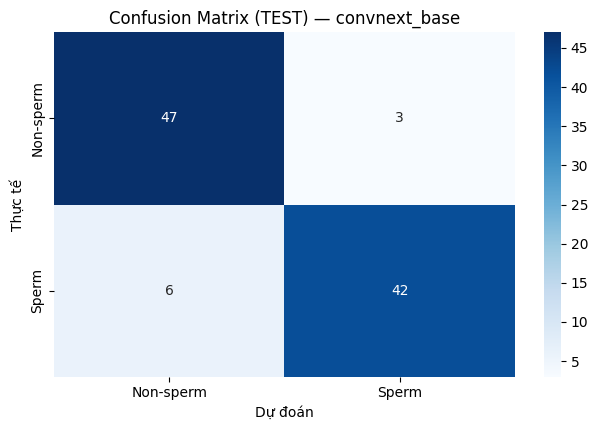

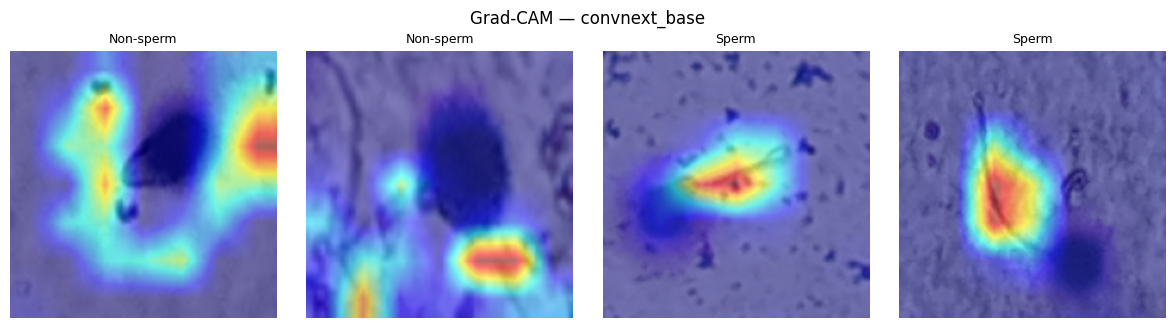

  ✅ [TaskA] resnet50         | Test Acc=0.9286 | Test Macro-F1=0.9286


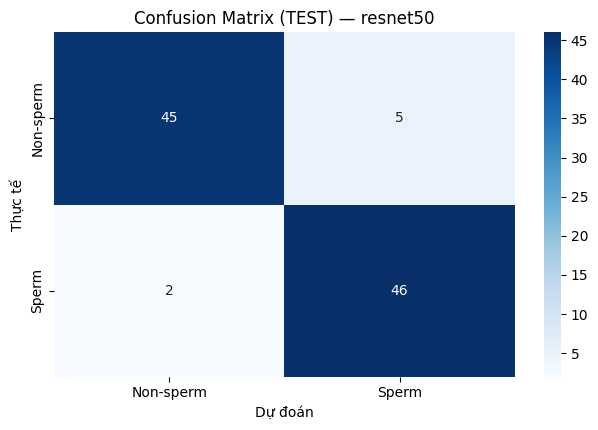

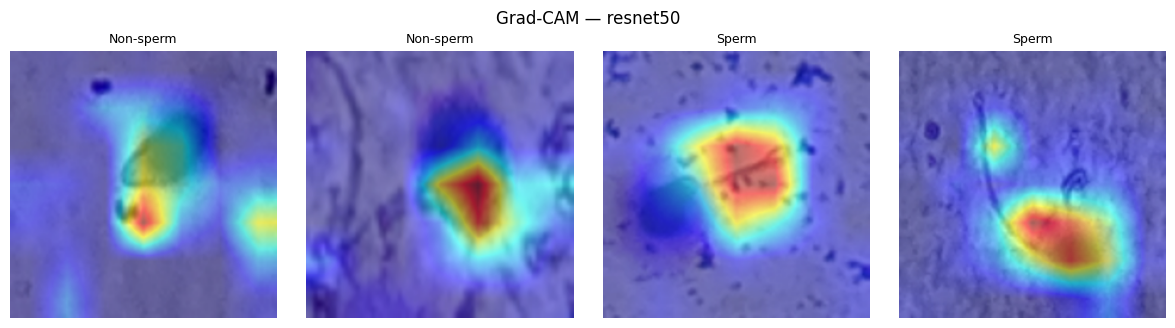

,model,acc,f1_macro,precision_macro,recall_macro
0,resnet50,0.9286,0.9286,0.9297,0.9292
1,convnext_base,0.9082,0.9079,0.9101,0.9075


In [11]:

print("🔎 Đang đánh giá toàn bộ model đã train của Task A trên tập TEST ...\n")
leaderboard_A = build_leaderboard("TaskA", MODELS_DIR_A, EVAL_DIR_A, test_list_A)
leaderboard_A


### 🏆 Bảng xếp hạng & model tốt nhất — Task A

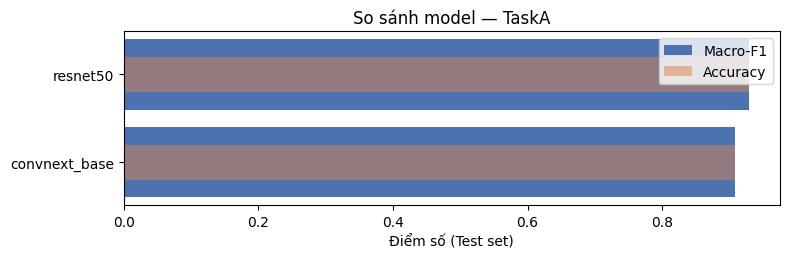

🏆 MODEL TỐT NHẤT — TASK A: 'resnet50' (Test Macro-F1=0.9286, Test Acc=0.9286)


,model,acc,f1_macro,precision_macro,recall_macro
0,resnet50,0.9286,0.9286,0.9297,0.9292
1,convnext_base,0.9082,0.9079,0.9101,0.9075


In [12]:

plot_leaderboard(leaderboard_A, "TaskA", EVAL_DIR_A)

if not leaderboard_A.empty:
    best_row_A = leaderboard_A.iloc[0]
    print(f"🏆 MODEL TỐT NHẤT — TASK A: '{best_row_A['model']}' "
          f"(Test Macro-F1={best_row_A['f1_macro']:.4f}, Test Acc={best_row_A['acc']:.4f})")
else:
    best_row_A = None
    print("Chưa có model nào để xếp hạng ở Task A.")

leaderboard_A



---
# 🅱️ SECTION — TASK B: DNA Fragmentation qua Halo Size (Multiclass)


In [13]:

SPLIT_JSON_B = f"{DATA_DRIVE_DIR}/taskB_split.json"
test_list_B = load_test_list(SPLIT_JSON_B, HALO_DIR)
print(f"Số ảnh trong tập TEST của Task B: {len(test_list_B)}")
pd.DataFrame(test_list_B, columns=["path", "class"]).groupby("class").size()


Số ảnh trong tập TEST của Task B: 61


,0
class,
Large halo,16
Medium halo,16
Small halo,14
Without halo,15


In [14]:

print("🔎 Đang đánh giá toàn bộ model đã train của Task B trên tập TEST ...\n")
leaderboard_B = build_leaderboard("TaskB", MODELS_DIR_B, EVAL_DIR_B, test_list_B)
leaderboard_B


Output hidden; open in https://colab.research.google.com to view.

### 🏆 Bảng xếp hạng & model tốt nhất — Task B

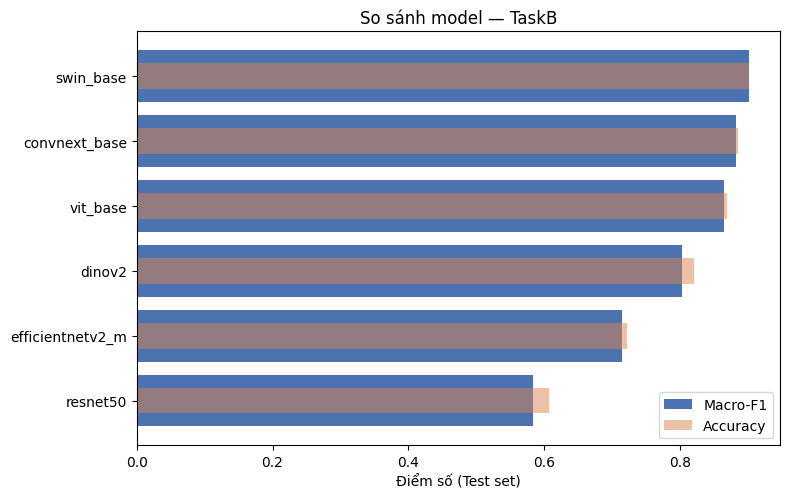

🏆 TOP 3 MODEL — TASK B:
   1. swin_base        | Test Macro-F1=0.9017 | Test Acc=0.9016
   2. convnext_base    | Test Macro-F1=0.8821 | Test Acc=0.8852
   3. vit_base         | Test Macro-F1=0.8641 | Test Acc=0.8689


,model,acc,f1_macro,precision_macro,recall_macro
0,swin_base,0.9016,0.9017,0.9045,0.9018
1,convnext_base,0.8852,0.8821,0.8832,0.8839
2,vit_base,0.8689,0.8641,0.8641,0.8650
3,dinov2,0.8197,0.8030,0.8061,0.8125
4,efficientnetv2_m,0.7213,0.7138,0.7425,0.7188
5,resnet50,0.6066,0.5826,0.6369,0.6027


In [15]:
plot_leaderboard(leaderboard_B, "TaskB", EVAL_DIR_B)

if not leaderboard_B.empty:
    best_row_B = leaderboard_B.iloc[0]
    top3_B = leaderboard_B.head(3)
    print("🏆 TOP 3 MODEL — TASK B:")
    for i, row in top3_B.iterrows():
        print(f"   {list(top3_B.index).index(i) + 1}. {row['model']:16s} "
              f"| Test Macro-F1={row['f1_macro']:.4f} | Test Acc={row['acc']:.4f}")
else:
    best_row_B = None
    top3_B = pd.DataFrame()
    print("Chưa có model nào để xếp hạng ở Task B.")

leaderboard_B

---
## 🧾 Tổng kết chung

In [16]:

print("="*60)
print("TỔNG KẾT BENCHMARK")
print("="*60)
if best_row_A is not None:
    print(f"Task A (Binary)     → Model tốt nhất: {best_row_A['model']:16s} "
          f"| Macro-F1={best_row_A['f1_macro']:.4f} | Acc={best_row_A['acc']:.4f}")
if best_row_B is not None:
    print(f"Task B (Multiclass) → Model tốt nhất: {best_row_B['model']:16s} "
          f"| Macro-F1={best_row_B['f1_macro']:.4f} | Acc={best_row_B['acc']:.4f}")
print("\nToàn bộ chi tiết (confusion matrix, classification report, Grad-CAM, leaderboard.csv) "
      f"đã được lưu tại:\n  {EVAL_DIR_A}\n  {EVAL_DIR_B}")


TỔNG KẾT BENCHMARK
Task A (Binary)     → Model tốt nhất: resnet50         | Macro-F1=0.9286 | Acc=0.9286
Task B (Multiclass) → Model tốt nhất: swin_base        | Macro-F1=0.9017 | Acc=0.9016

Toàn bộ chi tiết (confusion matrix, classification report, Grad-CAM, leaderboard.csv) đã được lưu tại:
  /content/drive/MyDrive/SpermAI_Benchmark/outputs/Evaluation/TaskA
  /content/drive/MyDrive/SpermAI_Benchmark/outputs/Evaluation/TaskB


In [17]:
# ================= TỔNG HỢP KẾT QUẢ TẤT CẢ MODEL CỦA 2 TASK =================

def build_all_classification_reports(eval_dirs):
    """Gom toàn bộ test_classification_report.csv của các model trong 2 Task vào một bảng."""
    all_reports = []

    for task_label, eval_dir in eval_dirs.items():

        if not os.path.isdir(eval_dir):
            continue

        for model_key in sorted(os.listdir(eval_dir)):

            model_dir = os.path.join(eval_dir, model_key)
            report_path = os.path.join(model_dir, "test_classification_report.csv")

            if not os.path.isfile(report_path):
                continue

            report_df = pd.read_csv(report_path, index_col=0)
            report_df.index.name = "class"

            report_df = report_df.reset_index()
            report_df.insert(0, "task", task_label)
            report_df.insert(1, "model", model_key)

            all_reports.append(report_df)

    if not all_reports:
        print("⚠️ Không tìm thấy file test_classification_report.csv nào.")
        return pd.DataFrame()

    all_reports_df = pd.concat(all_reports, ignore_index=True)

    return all_reports_df


all_reports_df = build_all_classification_reports({
    "TaskA": EVAL_DIR_A,
    "TaskB": EVAL_DIR_B
})

if not all_reports_df.empty:

    print("\n" + "=" * 100)
    print("TỔNG HỢP CLASSIFICATION REPORT — TẤT CẢ MODEL / 2 TASK")
    print("=" * 100)

    display(all_reports_df)

    all_reports_path = os.path.join(
        EVAL_DIR_A,
        "ALL_TASKS_classification_reports.csv"
    )

    all_reports_df.to_csv(all_reports_path, index=False)

    print(f"\n✅ Đã lưu bảng tổng hợp tại:")
    print(f"   {all_reports_path}")

else:

    print("Chưa có dữ liệu classification report để tổng hợp.")


TỔNG HỢP CLASSIFICATION REPORT — TẤT CẢ MODEL / 2 TASK


,task,model,class,precision,recall,f1-score,support
0,TaskA,convnext_base,Non-sperm,0.886792,0.940000,0.912621,50.000000
1,TaskA,convnext_base,Sperm,0.933333,0.875000,0.903226,48.000000
2,TaskA,convnext_base,accuracy,0.908163,0.908163,0.908163,0.908163
3,TaskA,convnext_base,macro avg,0.910063,0.907500,0.907924,98.000000
4,TaskA,convnext_base,weighted avg,0.909588,0.908163,0.908019,98.000000
5,TaskA,resnet50,Non-sperm,0.957447,0.900000,0.927835,50.000000
6,TaskA,resnet50,Sperm,0.901961,0.958333,0.929293,48.000000
7,TaskA,resnet50,accuracy,0.928571,0.928571,0.928571,0.928571
8,TaskA,resnet50,macro avg,0.929704,0.929167,0.928564,98.000000
9,TaskA,resnet50,weighted avg,0.930270,0.928571,0.928549,98.000000



✅ Đã lưu bảng tổng hợp tại:
   /content/drive/MyDrive/SpermAI_Benchmark/outputs/Evaluation/TaskA/ALL_TASKS_classification_reports.csv


In [18]:
if not all_reports_df.empty:

    all_reports_xlsx = os.path.join(
        EVAL_DIR_A,
        "ALL_TASKS_evaluation_results.xlsx"
    )

    with pd.ExcelWriter(all_reports_xlsx, engine="openpyxl") as writer:

        all_reports_df.to_excel(
            writer,
            sheet_name="All Reports",
            index=False
        )

        all_reports_df[all_reports_df["task"] == "TaskA"].to_excel(
            writer,
            sheet_name="Task A",
            index=False
        )

        all_reports_df[all_reports_df["task"] == "TaskB"].to_excel(
            writer,
            sheet_name="Task B",
            index=False
        )

        leaderboard_A.to_excel(
            writer,
            sheet_name="Leaderboard A",
            index=False
        )

        leaderboard_B.to_excel(
            writer,
            sheet_name="Leaderboard B",
            index=False
        )

    print(f"✅ Đã lưu file Excel tổng hợp tại:")
    print(f"   {all_reports_xlsx}")

✅ Đã lưu file Excel tổng hợp tại:
   /content/drive/MyDrive/SpermAI_Benchmark/outputs/Evaluation/TaskA/ALL_TASKS_evaluation_results.xlsx
